In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [62]:
np.random.seed(42) # Random seed , yo use garyo bhane jati choti run gareni same result aucha

In [63]:
print('libraries imported')

libraries imported


In [64]:


n = 200
# 1. Features generate gara:
# area → random between 500 to 4000 (use np.random.randint)
# bedrooms → random between 1 to 6
# age → random between 0 to 50

area = np.random.randint(500, 4000, size=n)      # 200 values, range 500-4000
bedrooms = np.random.randint(1, 7, size=n)        # 200 values, range 1-6 (7 excluded)
age = np.random.randint(0, 51, size=n)            # 200 values, range 0-50 (51 excluded)

print(f"area shape: {area.shape}")       # (200,) auney
print(f"area min: {area.min()}, max: {area.max()}")  # 500-3999 range ma
print(f"bedrooms unique: {np.unique(bedrooms)}")
     # [1,2,3,4,5,6]
print(f"age unique: {np.unique(age)}")
     # [0,1,2,3,4,




area shape: (200,)
area min: 521, max: 3999
bedrooms unique: [1 2 3 4 5 6]
age unique: [ 0  1  2  3  4  5  6  7  8  9 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 38 39 40 41 42 43 44 45 46 47 48 49
 50]


In [65]:
# 2. Price calculate gara (realistic formula):
# price = (area * 120) + (bedrooms * 8000) - (age * 1500) + noise
# noise le data realistic banaucha

noise = np.random.normal(0,15000,n)
price = (area * 120) + (bedrooms * 8000) - (age * 1500) + noise

df=pd.DataFrame({'area':area,'bedrooms':bedrooms,'age':age,'price':price})

print(f'dataset shape: {df.shape}')
print(f'\nfirst 5 rows:')
print(df.head())
print(f'\nlast 5 rows:')
print(df.tail())
print(f'\nunique values:')
print(df.nunique())
print(f'\ninfo:')
print(df.info())
print(f'\ndescribe:')
print(df.describe())


dataset shape: (200, 4)

first 5 rows:
   area  bedrooms  age          price
0  3674         4   20  456373.998131
1  1360         4   31  153309.492813
2  1794         6   22  242472.931783
3  1630         6   32  205044.432629
4  1595         3    2  199965.074836

last 5 rows:
     area  bedrooms  age          price
195  3560         5   50  414399.162083
196  3193         3   40  348320.524615
197  1295         4    6  165480.736980
198  1551         1    3  212466.861159
199  2143         4   49  223743.650655

unique values:
area        197
bedrooms      6
age          49
price       200
dtype: int64

info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   area      200 non-null    int64  
 1   bedrooms  200 non-null    int64  
 2   age       200 non-null    int64  
 3   price     200 non-null    float64
dtypes: float64(1), int64(3)
memory usage

In [66]:
#utility function

def normalize(X):
  mean =np.mean(X,axis=0)
  std = np.std(X,axis=0)
  X_normalised = (X-mean)/std
  return X_normalised,mean,std


In [67]:

def train_test_split(X, y, test_size=0.2):
    """
    Data lai train (80%) ra test (20%) ma split garcha
    Shuffle pani garcha so that data random hos
    """
    # Step 1: Indices banau ra shuffle gara
    indices = np.arange(len(X))
    np.random.shuffle(indices)

    # Step 2: Split point calculate gara
    split = int(len(X) * (1 - test_size))

     # Step 3: Split gara using indices
    X_train = X[indices[:split]]
    y_train = y[indices[:split]]
    X_test = X[indices[split:]]
    y_test = y[indices[split:]]

    return X_train, X_test, y_train, y_test


# 📊 Train-Test Split Concept

Machine Learning ma hami sanga bhayeko data lai hami direct single model ma haldainau. Yeslai hami **Training Set** (80%) ra **Testing Set** (20%) ma split garchhau.

---

## 🏫 Simple Analogy: Board Exam preparation

Imagine gara, timro course book ma **100 wata questions** chhan:
* **Training Set (80 Questions)**: Timi le din-raat practice gareko questions haru. Timi le yasko answer key check gardai mistake correction garchhau.
* **Testing Set (20 Questions)**: Exam hall ma aune naya questions. Timi le yo questions pahila kahilyai dekheko chainau.

> ⚠️ **Kina split gareko?** Yadi hami le practice garekai 80 questions bata matra exam liyau bhane, timi le answer "memorize" (ghokera) gareko ho ki "concept bujheko" ho thaha hudaina. Naya questions ma test garesi matra thaha hunchha ki timro model le real ma predictive concept bujhyo ki nai!

---

## ❓ 1. Ke sadhai 80% Train ra 20% Test nai linu parchha?

**Hoina!** Yo koi strict rule haina. Yo standard rule of thumb matra ho.
* Data size medium (100 - 10,000 rows) chha bhane: **80/20** or **70/30** common hunchha.
* Data size ekdam thulo (1 Million+ rows) chha bhane: **99/1** split pani garna sakincha (1% test data = 10,000 houses evaluation ko lagi kaafi hunchha).

---

## ❓ 2. Shuffling ra Indices banako logic k ho?

Hami le split garna bhanda pahila indices banayera shuffle gareko code yesto thiyo:
```python
indices = np.arange(len(X))   # [0, 1, 2, ..., 199]
np.random.shuffle(indices)    # Shuffled to e.g., [42, 117, 3, 199, ...]

In [68]:

# Features ra Target separate gara
X = df[['area', 'bedrooms', 'age']].values    # .values le numpy array banaucha
y = df['price'].values
# Normalize gara
X_norm, X_mean, X_std = normalize(X)


In [69]:

# Split gara
X_train, X_test, y_train, y_test = train_test_split(X_norm, y, test_size=0.2)
print(f"X_train shape: {X_train.shape}")   # (160, 3) auney
print(f"X_test shape: {X_test.shape}")      # (40, 3) auney
print(f"Normalized mean ≈ 0: {np.mean(X_norm, axis=0).round(3)}")
print(f"Normalized std ≈ 1: {np.std(X_norm, axis=0).round(2)}")

X_train shape: (160, 3)
X_test shape: (40, 3)
Normalized mean ≈ 0: [-0.  0.  0.]
Normalized std ≈ 1: [1. 1. 1.]


In [70]:
# ============================================
# CELL 4: Linear Regression from Scratch
# ============================================
import numpy as np

class LinearRegression:

    def __init__(self, learning_rate=0.01, epochs=1000):
        """Model initialize gara"""
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.cost_history = []   # Training loss track garna


    def predict(self, X):
        """
        Prediction formula: y_hat = X · W + b
        """
        return np.dot(X, self.weights) + self.bias


    def compute_cost(self, y_true, y_pred):
        """
        Mean Squared Error (MSE)
        Formula: MSE = (1/n) * Σ(y_true - y_pred)²
        """
        cost = np.mean((y_true - y_pred) ** 2)
        return cost


    def fit(self, X, y):
        """
        ⭐ GRADIENT DESCENT — Model train garcha
        """
        n_samples, n_features = X.shape

        # Initialize weights to zeros
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.cost_history = []

        # Training loop
        for epoch in range(self.epochs):

            # Step 1: Predict
            y_pred = self.predict(X)

            # Step 2: Compute cost
            cost = self.compute_cost(y, y_pred)
            self.cost_history.append(cost)

            # Step 3: Compute gradients
            dw = (2 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (2 / n_samples) * np.sum(y_pred - y)

            # Step 4: Update weights and bias
            self.weights = self.weights - self.learning_rate * dw
            self.bias = self.bias - self.learning_rate * db

            # Print every 100 epochs
            if epoch % 100 == 0:
                print(f"Epoch {epoch:04d}/{self.epochs} — Cost: {cost:.2f}")

        print(f"\n✅ Training complete!")
        print(f"Final Cost: {self.cost_history[-1]:.2f}")


    def r2_score(self, y_true, y_pred):
        """
        R² Score — Model accuracy (0 index bad, 1 perfect)
        """
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        return 1 - (ss_res / ss_tot)


# -------- READY! --------
print("✅ LinearRegression class ready!")

✅ LinearRegression class ready!


In [71]:
# ============================================
# CELL 5: Train the Model
# ============================================

# 1. Model create gara
model = LinearRegression(learning_rate=0.01, epochs=1000)

# 2. Train gara
model.fit(X_train, y_train)

# 3. Test data ma predict gara
y_pred = model.predict(X_test)

# 4. Evaluate gara
mse = model.compute_cost(y_test, y_pred)
r2 = model.r2_score(y_test, y_pred)

print(f"\n📊 Results:")
print(f"   MSE:      {mse:,.2f}")
print(f"   R² Score: {r2:.4f}")
print(f"\n📐 Learned Weights:")
print(f"   Area weight:     {model.weights[0]:.4f}")
print(f"   Bedrooms weight: {model.weights[1]:.4f}")
print(f"   Age weight:      {model.weights[2]:.4f}")
print(f"   Bias:            {model.bias:.4f}")

Epoch 0000/1000 — Cost: 88527769542.17
Epoch 0100/1000 — Cost: 1717963603.17
Epoch 0200/1000 — Cost: 235283282.41
Epoch 0300/1000 — Cost: 209661005.78
Epoch 0400/1000 — Cost: 209213584.47
Epoch 0500/1000 — Cost: 209205699.02
Epoch 0600/1000 — Cost: 209205558.90
Epoch 0700/1000 — Cost: 209205556.40
Epoch 0800/1000 — Cost: 209205556.35
Epoch 0900/1000 — Cost: 209205556.35

✅ Training complete!
Final Cost: 209205556.35

📊 Results:
   MSE:      215,661,106.52
   R² Score: 0.9836

📐 Learned Weights:
   Area weight:     119622.5037
   Bedrooms weight: 14290.7839
   Age weight:      -22775.7494
   Bias:            269430.4176


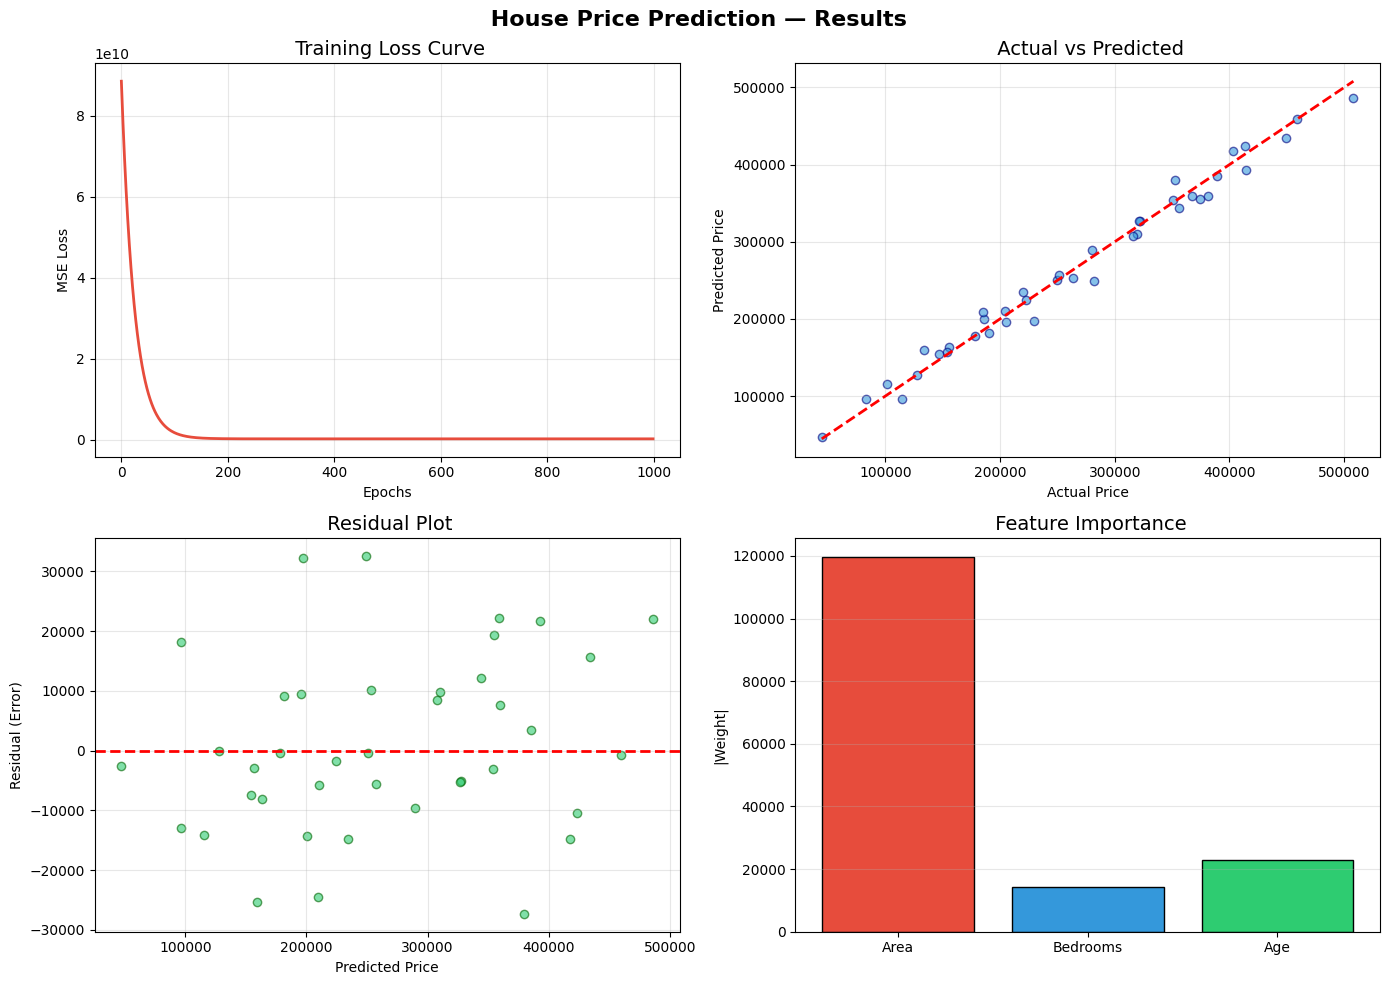

In [74]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ---- Plot 1: Loss vs Epochs ----
axes[0, 0].plot(model.cost_history, color='#e74c3c', linewidth=2)
axes[0, 0].set_title(' Training Loss Curve', fontsize=14)
axes[0, 0].set_xlabel('Epochs')
axes[0, 0].set_ylabel('MSE Loss')
axes[0, 0].grid(True, alpha=0.3)

# ---- Plot 2: Actual vs Predicted ----
axes[0, 1].scatter(y_test, y_pred, color='#3498db', alpha=0.6, edgecolors='navy')
# Perfect prediction line pani add gara (diagonal line):
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0, 1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2)
axes[0, 1].set_title(' Actual vs Predicted', fontsize=14)
axes[0, 1].set_xlabel('Actual Price')
axes[0, 1].set_ylabel('Predicted Price')
axes[0, 1].grid(True, alpha=0.3)

# ---- Plot 3: Residuals (Errors) ----
residuals =y_test - y_pred  # Hint: y_test - y_pred
axes[1, 0].scatter(y_pred, residuals, color='#2ecc71', alpha=0.6, edgecolors='darkgreen')
axes[1, 0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[1, 0].set_title(' Residual Plot', fontsize=14)
axes[1, 0].set_xlabel('Predicted Price')
axes[1, 0].set_ylabel('Residual (Error)')
axes[1, 0].grid(True, alpha=0.3)

# ---- Plot 4: Feature Importance (Bar Chart) ----
features = ['Area', 'Bedrooms', 'Age']
importance = np.abs(model.weights)
colors = ['#e74c3c', '#3498db', '#2ecc71']
axes[1, 1].bar(features, importance, color=colors, edgecolor='black')
axes[1, 1].set_title(' Feature Importance', fontsize=14)
axes[1, 1].set_ylabel('|Weight|')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.suptitle(' House Price Prediction — Results', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [75]:
# ============================================
# CELL 7: Interactive Prediction
# ============================================

# Note: Colab ma yo automatically available cha!
from ipywidgets import interact, IntSlider, FloatSlider
from IPython.display import display, HTML

def predict_price(area, bedrooms, age):
    """User input bata price predict garcha"""

    # Step 1: Input lai array banau
    user_input = np.array([[area, bedrooms, age]])

    # Step 2: NORMALIZE gara (training ma use gareko mean/std use gara!)
    user_input_norm = (user_input - X_mean) / X_std

    # Step 3: Predict gara
    predicted = model.predict(user_input_norm)

    # Step 4: Display gara
    print(f"{'='*40}")
    print(f" House Details:")
    print(f"   Area:     {area} sq ft")
    print(f"   Bedrooms: {bedrooms}")
    print(f"   Age:      {age} years")
    print(f"{'='*40}")
    print(f" Predicted Price: ${predicted[0]:,.2f}")
    print(f"{'='*40}")


# Interactive sliders banau
interact(
    predict_price,
    area=IntSlider(min=500, max=5000, step=100, value=1500, description='Area (sqft):'),
    bedrooms=IntSlider(min=1, max=6, step=1, value=3, description='Bedrooms:'),
    age=IntSlider(min=0, max=50, step=1, value=10, description='Age (yrs):')
);

interactive(children=(IntSlider(value=1500, description='Area (sqft):', max=5000, min=500, step=100), IntSlide…